# Experiment 2 — Ranking Loss + Freeze/Unfreeze + Patient CV

**Why Exp2:** Exp1 showed ResNet Top-3 ≈ 71% but Top-1 ≈ center baseline, EfficientNet overfit a 4-patient val set, and SimpleCNN collapsed. Independent soft-label BCE does not force *within-patient* ranking.

**Changes vs Exp1**
1. **Patient-level ListNet loss** — softmax over a patient's slices vs soft GT distribution
2. **Optional pairwise margin ranking** on best vs non-best
3. **ResNet18** with **freeze → unfreeze** schedule (drop SimpleCNN)
4. **Early stop on val MAE** (more stable than Top-1/3 on tiny val)
5. **Primary eval = 5-fold patient CV** + optional LOOCV; fold-score **ensemble**
6. Soft labels with wider sigma; optional **instance-index aux feature**
7. Milder aug (no horizontal flip by default)

**Runtime:** Kaggle GPU T4 recommended (~20–40 min for 5-fold; LOOCV longer). Outputs → `exp2_outputs/`.

### Kaggle
1. Attach the same dataset as Exp1 (`Dr-Dataset/` + cohort Excel)
2. Accelerator → GPU T4 → Run All


## 0. Install dependencies

In [1]:
import subprocess, sys

def _ensure(pkgs):
    missing = []
    for p, import_name in pkgs:
        try:
            __import__(import_name)
        except ImportError:
            missing.append(p)
    if missing:
        print("Installing:", missing)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

_ensure([
    ("pydicom", "pydicom"),
    ("openpyxl", "openpyxl"),
    ("pandas", "pandas"),
    ("scikit-learn", "sklearn"),
    ("matplotlib", "matplotlib"),
    ("seaborn", "seaborn"),
    ("tqdm", "tqdm"),
    ("pillow", "PIL"),
    ("torch", "torch"),
    ("torchvision", "torchvision"),
])
print("Dependencies OK")


Dependencies OK


## 1. Config & paths

In [2]:
from __future__ import annotations

import os, random, json, copy
from pathlib import Path
from dataclasses import dataclass, asdict, field

import numpy as np
import pandas as pd
import pydicom
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms as T
from torchvision import models

from sklearn.model_selection import StratifiedKFold, LeaveOneOut, train_test_split
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)

IS_KAGGLE = Path("/kaggle/input").exists()


def find_excel(root: Path) -> Path:
    patterns = ["**/1stcohortSAX*.xlsx", "**/*cohort*SAX*.xlsx", "**/*SAX*.xlsx"]
    for pat in patterns:
        hits = sorted(root.glob(pat))
        preferred = [h for h in hits if "cohort" in h.name.lower() or "1st" in h.name.lower()]
        pool = preferred or hits
        if pool:
            return pool[0]
    raise FileNotFoundError(f"No cohort Excel under {root}")


def find_dicom_root(root: Path) -> Path:
    hits = list(root.rglob("1st_cohort_SAX"))
    if hits:
        return hits[0]
    pats = [p for p in root.rglob("Patient-*") if p.is_dir()]
    if pats:
        return pats[0].parent
    raise FileNotFoundError(f"No DICOM cohort under {root}")


if IS_KAGGLE:
    INPUT_ROOT = Path("/kaggle/input")
    DATA_ROOT = None
    for c in sorted(INPUT_ROOT.iterdir()):
        try:
            find_dicom_root(c)
            DATA_ROOT = c
            break
        except FileNotFoundError:
            continue
    if DATA_ROOT is None:
        DATA_ROOT = next(INPUT_ROOT.iterdir())
    OUT_DIR = Path("/kaggle/working/exp2_outputs")
else:
    DATA_ROOT = Path(".").resolve()
    OUT_DIR = DATA_ROOT / "exp2_outputs"

OUT_DIR.mkdir(parents=True, exist_ok=True)
EXCEL_PATH = find_excel(DATA_ROOT)
DICOM_ROOT = find_dicom_root(DATA_ROOT)

print(f"IS_KAGGLE  = {IS_KAGGLE}")
print(f"DATA_ROOT  = {DATA_ROOT}")
print(f"EXCEL_PATH = {EXCEL_PATH}")
print(f"DICOM_ROOT = {DICOM_ROOT}")
print(f"OUT_DIR    = {OUT_DIR}")


IS_KAGGLE  = True
DATA_ROOT  = /kaggle/input/datasets
EXCEL_PATH = /kaggle/input/datasets/muhammadmoazzamimran/dr-usmancardiodataset/1stcohortSAX (1).xlsx
DICOM_ROOT = /kaggle/input/datasets/muhammadmoazzamimran/dr-usmancardiodataset/Dr-Dataset/1st_cohort_SAX
OUT_DIR    = /kaggle/working/exp2_outputs


In [3]:
@dataclass
class CFG:
    seed: int = 42
    img_size: int = 224
    # Patient-level batching (each item = one patient stack)
    patient_batch_size: int = 4
    num_workers: int = 0
    epochs_freeze: int = 8
    epochs_unfreeze: int = 25
    lr_head: float = 1e-3
    lr_backbone: float = 1e-5
    weight_decay: float = 1e-4
    soft_label_sigma: float = 1.5
    pairwise_weight: float = 0.5   # 0 = ListNet only
    margin: float = 0.5
    early_stop_patience: int = 8
    use_instance_aux: bool = True
    hflip: bool = False            # off: frequency banding may be directional
    n_folds: int = 5
    run_loocv: bool = False        # True = slower, gold-standard for n=26
    run_holdout_demo: bool = True  # quick single-split sanity check
    holdout_test_size: float = 0.25
    model_name: str = "resnet18"
    device: str = "cuda" if torch.cuda.is_available() else "cpu"

cfg = CFG()

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(cfg.seed)
DEVICE = torch.device(cfg.device)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print(json.dumps(asdict(cfg), indent=2))


Device: cuda
GPU: Tesla T4
{
  "seed": 42,
  "img_size": 224,
  "patient_batch_size": 4,
  "num_workers": 0,
  "epochs_freeze": 8,
  "epochs_unfreeze": 25,
  "lr_head": 0.001,
  "lr_backbone": 1e-05,
  "weight_decay": 0.0001,
  "soft_label_sigma": 1.5,
  "pairwise_weight": 0.5,
  "margin": 0.5,
  "early_stop_patience": 8,
  "use_instance_aux": true,
  "hflip": false,
  "n_folds": 5,
  "run_loocv": false,
  "run_holdout_demo": true,
  "holdout_test_size": 0.25,
  "model_name": "resnet18",
  "device": "cuda"
}


## 2. Labels & slice index

In [4]:
def load_labels(excel_path: Path) -> pd.DataFrame:
    raw = pd.read_excel(excel_path, header=None)
    header_idx = None
    for i, row in raw.iterrows():
        vals = [str(v).strip() if pd.notna(v) else "" for v in row.tolist()]
        if "Anonymized ID" in vals:
            header_idx = i
            break
    if header_idx is None:
        raise ValueError("Header 'Anonymized ID' not found")
    df = pd.read_excel(excel_path, header=header_idx)
    df = df.dropna(axis=1, how="all").dropna(subset=["Anonymized ID"]).reset_index(drop=True)
    df = df.rename(columns={
        "Anonymized ID": "patient_id",
        "Plane": "plane",
        "Max Freq (Hz)": "max_freq",
        "Freq Step (Hz)": "freq_step",
        "Min Freq (Hz)": "min_freq",
        "Manual frequency (Hz)": "manual_freq",
        "image no": "gt_image_no",
    })
    df["gt_image_no"] = df["gt_image_no"].astype(int)
    df["n_expected"] = ((df["max_freq"] - df["min_freq"]) / df["freq_step"]).astype(int) + 1
    df["protocol"] = np.where(df["freq_step"] == 25, "step25", "atypical")
    return df


def parse_instance_from_name(path: Path) -> int | None:
    name = path.name
    if name.lower().startswith("img"):
        digits = ""
        for ch in name[3:]:
            if ch.isdigit():
                digits += ch
            else:
                break
        return int(digits) if digits else None
    return None


def build_slice_index(dicom_root: Path, labels: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for _, lab in labels.iterrows():
        pid = lab["patient_id"]
        pdir = dicom_root / pid
        if not pdir.exists():
            matches = [d for d in dicom_root.iterdir() if d.is_dir() and d.name.lower() == pid.lower()]
            if not matches:
                print("WARNING missing", pid)
                continue
            pdir = matches[0]
        for f in sorted(pdir.glob("*.dcm")):
            inst = parse_instance_from_name(f)
            if inst is None:
                ds = pydicom.dcmread(f, stop_before_pixels=True)
                inst = int(getattr(ds, "InstanceNumber", 0))
            dist = abs(inst - int(lab["gt_image_no"]))
            soft = float(np.exp(-0.5 * (dist / cfg.soft_label_sigma) ** 2))
            rows.append({
                "patient_id": pid,
                "path": str(f),
                "instance_no": inst,
                "gt_image_no": int(lab["gt_image_no"]),
                "manual_freq": lab["manual_freq"],
                "freq_step": lab["freq_step"],
                "protocol": lab["protocol"],
                "is_best": int(inst == int(lab["gt_image_no"])),
                "soft_label": soft,
                "abs_dist": dist,
            })
    return pd.DataFrame(rows)


labels_df = load_labels(EXCEL_PATH)
index_df = build_slice_index(DICOM_ROOT, labels_df)
print(labels_df[["patient_id", "gt_image_no", "manual_freq", "freq_step", "protocol"]].to_string(index=False))
print(f"\nPatients={len(labels_df)}  slices={len(index_df)}  "
      f"best_ok={index_df.groupby('patient_id')['is_best'].sum().eq(1).all()}")


  patient_id  gt_image_no  manual_freq  freq_step protocol
 Patient-BEV            7            0         25   step25
 Patient-BGT            7            0         25   step25
 Patient-BVE            6           25         25   step25
 Patient-CEA            7            0         25   step25
Patient-CEJP            4           75         25   step25
 Patient-DEM            9          -50         25   step25
 Patient-FAJ            9          -50         25   step25
 Patient-FEC            8          -25         25   step25
  Patient-GJ            9          -50         25   step25
 Patient-HMJ            8          -25         25   step25
 Patient-HRJ            7            0         25   step25
 Patient-IAM            8          -25         25   step25
 Patient-INA           11         -100         25   step25
  Patient-KP            6         -100         50 atypical
  Patient-MJ            7            0         25   step25
  Patient-MS            9          -50         25   step

## 3. Patient-stack dataset

In [5]:
def load_dicom_image(path: str) -> np.ndarray:
    arr = pydicom.dcmread(path).pixel_array.astype(np.float32)
    p1, p99 = np.percentile(arr, (1, 99))
    return np.clip((arr - p1) / max(p99 - p1, 1e-6), 0, 1)


IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def make_transforms(train: bool):
    ops = [T.Resize((cfg.img_size, cfg.img_size))]
    if train:
        if cfg.hflip:
            ops.append(T.RandomHorizontalFlip(p=0.5))
        ops.append(T.RandomAffine(degrees=6, translate=(0.04, 0.04), scale=(0.96, 1.04)))
        ops.append(T.ColorJitter(brightness=0.12, contrast=0.12))
    ops += [T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
    return T.Compose(ops)


class PatientStackDataset(Dataset):
    """One item = all scout slices for one patient (variable length)."""

    def __init__(self, index: pd.DataFrame, patient_ids: list[str], train: bool = False):
        self.train = train
        self.tf = make_transforms(train)
        self.groups = []
        for pid in patient_ids:
            g = index[index["patient_id"] == pid].sort_values("instance_no").reset_index(drop=True)
            if len(g) == 0:
                continue
            self.groups.append(g)

    def __len__(self):
        return len(self.groups)

    def __getitem__(self, idx):
        g = self.groups[idx]
        imgs, softs, insts, fracs = [], [], [], []
        n = len(g)
        for _, r in g.iterrows():
            arr = (load_dicom_image(r["path"]) * 255).astype(np.uint8)
            img = self.tf(Image.fromarray(arr).convert("RGB"))
            imgs.append(img)
            softs.append(float(r["soft_label"]))
            insts.append(int(r["instance_no"]))
            fracs.append(float(r["instance_no"]) / max(n, 1))
        return {
            "images": torch.stack(imgs, 0),          # [S,3,H,W]
            "soft": torch.tensor(softs, dtype=torch.float32),
            "instance_no": torch.tensor(insts, dtype=torch.long),
            "frac": torch.tensor(fracs, dtype=torch.float32),
            "gt_image_no": int(g["gt_image_no"].iloc[0]),
            "patient_id": str(g["patient_id"].iloc[0]),
            "protocol": str(g["protocol"].iloc[0]),
            "n": n,
        }


def collate_patients(batch):
    """Pad variable-length stacks to max S in batch; return mask."""
    max_s = max(b["n"] for b in batch)
    B = len(batch)
    C, H, W = batch[0]["images"].shape[1:]
    images = torch.zeros(B, max_s, C, H, W)
    soft = torch.zeros(B, max_s)
    frac = torch.zeros(B, max_s)
    inst = torch.zeros(B, max_s, dtype=torch.long)
    mask = torch.zeros(B, max_s, dtype=torch.bool)
    gt = []
    pids = []
    protocols = []
    for i, b in enumerate(batch):
        s = b["n"]
        images[i, :s] = b["images"]
        soft[i, :s] = b["soft"]
        frac[i, :s] = b["frac"]
        inst[i, :s] = b["instance_no"]
        mask[i, :s] = True
        gt.append(b["gt_image_no"])
        pids.append(b["patient_id"])
        protocols.append(b["protocol"])
    return {
        "images": images,
        "soft": soft,
        "frac": frac,
        "instance_no": inst,
        "mask": mask,
        "gt_image_no": torch.tensor(gt, dtype=torch.long),
        "patient_id": pids,
        "protocol": protocols,
    }


def make_loader(index, pids, train: bool, shuffle: bool):
    ds = PatientStackDataset(index, pids, train=train)
    return DataLoader(
        ds,
        batch_size=cfg.patient_batch_size,
        shuffle=shuffle,
        num_workers=cfg.num_workers,
        collate_fn=collate_patients,
        pin_memory=(DEVICE.type == "cuda"),
    )

# smoke
_demo = make_loader(index_df, labels_df["patient_id"].tolist()[:4], train=True, shuffle=True)
b = next(iter(_demo))
print("batch images", tuple(b["images"].shape), "mask", b["mask"].sum(1).tolist())


batch images (4, 13, 3, 224, 224) mask [13, 12, 13, 13]


## 4. Model — ResNet18 scorer with optional instance aux

In [6]:
class SliceScorer(nn.Module):
    def __init__(self, use_aux: bool = True):
        super().__init__()
        self.use_aux = use_aux
        try:
            weights = models.ResNet18_Weights.IMAGENET1K_V1
            backbone = models.resnet18(weights=weights)
        except Exception:
            backbone = models.resnet18(pretrained=True)
        feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        in_dim = feat_dim + (1 if use_aux else 0)
        self.head = nn.Sequential(
            nn.Dropout(0.25),
            nn.Linear(in_dim, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
        )

    def freeze_backbone(self):
        for p in self.backbone.parameters():
            p.requires_grad = False

    def unfreeze_backbone(self):
        for p in self.backbone.parameters():
            p.requires_grad = True

    def forward(self, images: torch.Tensor, frac: torch.Tensor | None = None,
                mask: torch.Tensor | None = None) -> torch.Tensor:
        # images: [B,S,3,H,W] or [S,3,H,W]
        squeeze = False
        if images.ndim == 4:
            images = images.unsqueeze(0)
            if frac is not None and frac.ndim == 1:
                frac = frac.unsqueeze(0)
            if mask is not None and mask.ndim == 1:
                mask = mask.unsqueeze(0)
            squeeze = True
        B, S, C, H, W = images.shape
        x = images.reshape(B * S, C, H, W)
        feat = self.backbone(x)  # [B*S, 512]
        if self.use_aux:
            if frac is None:
                raise ValueError("frac required when use_aux=True")
            f = frac.reshape(B * S, 1)
            feat = torch.cat([feat, f], dim=1)
        scores = self.head(feat).reshape(B, S)
        if mask is not None:
            scores = scores.masked_fill(~mask, -1e4)
        return scores.squeeze(0) if squeeze else scores


def build_model() -> SliceScorer:
    return SliceScorer(use_aux=cfg.use_instance_aux).to(DEVICE)


m = build_model()
with torch.no_grad():
    sc = m(b["images"].to(DEVICE), b["frac"].to(DEVICE), b["mask"].to(DEVICE))
print("scores", tuple(sc.shape), "params", sum(p.numel() for p in m.parameters()))
del m
torch.cuda.empty_cache() if DEVICE.type == "cuda" else None


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 161MB/s]


scores (4, 13) params 11209473


## 5. Losses & metrics

**ListNet:** softmax over valid slices vs renormalized soft labels (teaches relative ranking).  
**Pairwise:** `softplus(margin - (s_best - s_other))` averaged over non-best slices.


In [7]:
def listnet_loss(scores: torch.Tensor, soft: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    # scores/soft/mask: [B,S]
    neg_inf = torch.finfo(scores.dtype).min / 4
    scores_m = scores.masked_fill(~mask, neg_inf)
    soft_m = soft.masked_fill(~mask, 0.0)
    # target distribution
    soft_m = soft_m / soft_m.sum(dim=1, keepdim=True).clamp_min(1e-8)
    log_p = F.log_softmax(scores_m, dim=1)
    # only accumulate where mask (log_softmax already ~0 mass on padded via -inf)
    loss = -(soft_m * log_p).sum(dim=1)
    return loss.mean()


def pairwise_margin_loss(scores: torch.Tensor, instance_no: torch.Tensor,
                         gt: torch.Tensor, mask: torch.Tensor, margin: float) -> torch.Tensor:
    losses = []
    B = scores.size(0)
    for i in range(B):
        m = mask[i]
        s = scores[i][m]
        inst = instance_no[i][m]
        g = int(gt[i].item())
        best_idx = (inst == g).nonzero(as_tuple=False)
        if len(best_idx) == 0:
            continue
        s_best = s[best_idx[0, 0]]
        others = s[inst != g]
        if len(others) == 0:
            continue
        # hinge via softplus for smooth grads
        losses.append(F.softplus(margin - (s_best - others)).mean())
    if not losses:
        return scores.new_tensor(0.0)
    return torch.stack(losses).mean()


def combined_loss(scores, soft, frac, instance_no, gt, mask):
    loss = listnet_loss(scores, soft, mask)
    if cfg.pairwise_weight > 0:
        loss = loss + cfg.pairwise_weight * pairwise_margin_loss(
            scores, instance_no, gt, mask, cfg.margin
        )
    return loss


@torch.no_grad()
def predict_patients(model: nn.Module, index: pd.DataFrame, pids: list[str]) -> pd.DataFrame:
    model.eval()
    loader = make_loader(index, pids, train=False, shuffle=False)
    rows = []
    for batch in loader:
        images = batch["images"].to(DEVICE)
        frac = batch["frac"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)
        scores = model(images, frac, mask)  # [B,S]
        for i, pid in enumerate(batch["patient_id"]):
            m = mask[i].cpu().numpy()
            inst = batch["instance_no"][i].cpu().numpy()[m]
            sc = scores[i].cpu().numpy()[m]
            gt = int(batch["gt_image_no"][i].item())
            for ii, ss in zip(inst, sc):
                rows.append({
                    "patient_id": pid,
                    "instance_no": int(ii),
                    "gt_image_no": gt,
                    "score": float(ss),
                    "protocol": batch["protocol"][i],
                })
    return pd.DataFrame(rows)


def patient_ranking_metrics(pred_df: pd.DataFrame) -> dict:
    recs = []
    for pid, g in pred_df.groupby("patient_id"):
        g = g.sort_values("score", ascending=False)
        gt = int(g["gt_image_no"].iloc[0])
        ranked = g["instance_no"].astype(int).tolist()
        pred1 = ranked[0]
        hit1 = int(pred1 == gt)
        hit3 = int(gt in ranked[: min(3, len(ranked))])
        # rank of GT (1-based)
        rank_gt = ranked.index(gt) + 1 if gt in ranked else len(ranked)
        recs.append({
            "patient_id": pid,
            "protocol": g["protocol"].iloc[0] if "protocol" in g.columns else "unknown",
            "gt_image_no": gt,
            "pred_top1": pred1,
            "pred_top3": ranked[:3],
            "top1_correct": hit1,
            "top3_correct": hit3,
            "mae": abs(pred1 - gt),
            "rank_gt": rank_gt,
        })
    rdf = pd.DataFrame(recs)
    return {
        "top1_acc": float(rdf["top1_correct"].mean()) if len(rdf) else 0.0,
        "top3_acc": float(rdf["top3_correct"].mean()) if len(rdf) else 0.0,
        "mae": float(rdf["mae"].mean()) if len(rdf) else 0.0,
        "mean_rank_gt": float(rdf["rank_gt"].mean()) if len(rdf) else 0.0,
        "n_patients": len(rdf),
        "per_patient": rdf,
    }


def summarize_by_protocol(pred_df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for proto, g in pred_df.groupby("protocol"):
        m = patient_ranking_metrics(g)
        rows.append({"protocol": proto, "n": m["n_patients"],
                     "top1": m["top1_acc"], "top3": m["top3_acc"], "mae": m["mae"]})
    return pd.DataFrame(rows)


## 6. Train loop (freeze → unfreeze, early-stop on MAE)

In [8]:
def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    losses = []
    for batch in loader:
        images = batch["images"].to(DEVICE)
        soft = batch["soft"].to(DEVICE)
        frac = batch["frac"].to(DEVICE)
        inst = batch["instance_no"].to(DEVICE)
        gt = batch["gt_image_no"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)
        with torch.set_grad_enabled(train):
            scores = model(images, frac, mask)
            loss = combined_loss(scores, soft, frac, inst, gt, mask)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()
        losses.append(float(loss.item()))
    return float(np.mean(losses)) if losses else 0.0


def train_fold(train_pids, val_pids, tag: str):
    print("\n" + "=" * 64)
    print(f"Train {tag}  n_train={len(train_pids)} n_val={len(val_pids)}")
    print("=" * 64)

    model = build_model()
    model.freeze_backbone()
    opt = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=cfg.lr_head, weight_decay=cfg.weight_decay,
    )

    tr_loader = make_loader(index_df, train_pids, train=True, shuffle=True)
    # tiny val: use train subset if val empty
    if len(val_pids) == 0:
        val_pids = train_pids[: max(1, len(train_pids) // 5)]
    va_loader = make_loader(index_df, val_pids, train=False, shuffle=False)

    history = []
    best_mae = float("inf")
    best_state = None
    patience = 0
    phase_epochs = [("freeze", cfg.epochs_freeze), ("unfreeze", cfg.epochs_unfreeze)]
    global_epoch = 0

    for phase, n_epochs in phase_epochs:
        if phase == "unfreeze":
            model.unfreeze_backbone()
            opt = torch.optim.AdamW([
                {"params": model.backbone.parameters(), "lr": cfg.lr_backbone},
                {"params": model.head.parameters(), "lr": cfg.lr_head * 0.3},
            ], weight_decay=cfg.weight_decay)
            patience = 0  # reset: freeze plateau must not burn unfreeze budget
            print(f"-- unfreeze backbone @ epoch {global_epoch + 1}")

        for _ in range(n_epochs):
            global_epoch += 1
            tr_loss = run_epoch(model, tr_loader, opt)
            va_loss = run_epoch(model, va_loader, optimizer=None)
            pred = predict_patients(model, index_df, val_pids)
            metrics = patient_ranking_metrics(pred)
            history.append({
                "epoch": global_epoch, "phase": phase,
                "train_loss": tr_loss, "val_loss": va_loss,
                "val_top1": metrics["top1_acc"], "val_top3": metrics["top3_acc"],
                "val_mae": metrics["mae"], "val_mean_rank": metrics["mean_rank_gt"],
            })
            improved = metrics["mae"] < best_mae - 1e-6
            if improved:
                best_mae = metrics["mae"]
                best_state = copy.deepcopy(model.state_dict())
                patience = 0
            else:
                patience += 1
            if global_epoch == 1 or global_epoch % 4 == 0 or improved:
                print(
                    f"Ep {global_epoch:02d} [{phase:8s}] "
                    f"tr={tr_loss:.4f} va={va_loss:.4f} "
                    f"Top1={metrics['top1_acc']:.3f} Top3={metrics['top3_acc']:.3f} "
                    f"MAE={metrics['mae']:.2f} rank={metrics['mean_rank_gt']:.2f}"
                    + (" *best*" if improved else "")
                )
            if patience >= cfg.early_stop_patience and phase == "unfreeze":
                print(f"Early stop at epoch {global_epoch}")
                break
        if patience >= cfg.early_stop_patience and phase == "unfreeze":
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    ckpt = OUT_DIR / f"resnet18_{tag}_best.pt"
    torch.save({"model": model.state_dict(), "cfg": asdict(cfg), "tag": tag}, ckpt)
    pd.DataFrame(history).to_csv(OUT_DIR / f"history_{tag}.csv", index=False)
    print("Saved", ckpt)
    return model, pd.DataFrame(history)


## 7. Holdout demo (sanity check, same spirit as Exp1)

In [9]:
holdout_results = None
holdout_per_patient = None

if cfg.run_holdout_demo:
    patients = labels_df["patient_id"].tolist()
    strata = pd.qcut(labels_df["gt_image_no"], q=min(3, len(patients) // 3), duplicates="drop").astype(str)
    train_pids, test_pids = train_test_split(
        patients, test_size=cfg.holdout_test_size, random_state=cfg.seed, stratify=strata
    )
    train_pids2, val_pids = train_test_split(train_pids, test_size=0.2, random_state=cfg.seed)

    model, hist = train_fold(train_pids2, val_pids, tag="holdout")
    pred = predict_patients(model, index_df, test_pids)
    metrics = patient_ranking_metrics(pred)
    holdout_per_patient = metrics["per_patient"]
    holdout_results = {
        "setting": "holdout",
        "top1_acc": metrics["top1_acc"],
        "top3_acc": metrics["top3_acc"],
        "mae": metrics["mae"],
        "mean_rank_gt": metrics["mean_rank_gt"],
        "n_test": metrics["n_patients"],
    }
    print("\n>>> HOLDOUT TEST", holdout_results)
    display(holdout_per_patient)
    display(summarize_by_protocol(pred))

    # baselines on same test patients
    def baseline_center(pids):
        rows = []
        for pid in pids:
            g = index_df[index_df["patient_id"] == pid]
            inst = sorted(g["instance_no"].tolist())
            gt = int(g["gt_image_no"].iloc[0])
            pred = inst[len(inst) // 2]
            neigh = sorted(inst, key=lambda i: (abs(i - pred), i))[:3]
            rows.append({"top1": int(pred == gt), "top3": int(gt in neigh), "mae": abs(pred - gt)})
        r = pd.DataFrame(rows)
        return {"top1_acc": r.top1.mean(), "top3_acc": r.top3.mean(), "mae": r.mae.mean()}

    print("Center baseline:", baseline_center(test_pids))
else:
    print("Holdout demo skipped")



Train holdout  n_train=15 n_val=4
Ep 01 [freeze  ] tr=2.9963 va=2.9180 Top1=0.000 Top3=0.750 MAE=2.50 rank=3.25 *best*
Ep 02 [freeze  ] tr=2.9019 va=2.8408 Top1=0.250 Top3=0.750 MAE=1.50 rank=2.75 *best*
Ep 03 [freeze  ] tr=2.7001 va=2.8012 Top1=0.500 Top3=0.500 MAE=0.50 rank=4.25 *best*
Ep 04 [freeze  ] tr=2.7265 va=2.7734 Top1=0.250 Top3=0.500 MAE=1.50 rank=4.75
Ep 08 [freeze  ] tr=2.4818 va=2.5686 Top1=0.250 Top3=0.500 MAE=1.50 rank=3.75
-- unfreeze backbone @ epoch 9
Ep 12 [unfreeze] tr=2.3535 va=2.5501 Top1=0.250 Top3=0.500 MAE=1.50 rank=3.75
Ep 16 [unfreeze] tr=2.2936 va=2.5204 Top1=0.250 Top3=0.500 MAE=2.00 rank=3.50
Early stop at epoch 16
Saved /kaggle/working/exp2_outputs/resnet18_holdout_best.pt

>>> HOLDOUT TEST {'setting': 'holdout', 'top1_acc': 0.14285714285714285, 'top3_acc': 0.42857142857142855, 'mae': 2.0, 'mean_rank_gt': 4.857142857142857, 'n_test': 7}


,patient_id,protocol,gt_image_no,pred_top1,pred_top3,top1_correct,top3_correct,mae,rank_gt
0,Patient-CEA,step25,7,4,"[4, 6, 7]",0,1,3,3
1,Patient-CEJP,step25,4,2,"[2, 13, 12]",0,0,2,4
2,Patient-IAM,step25,8,5,"[5, 11, 12]",0,0,3,5
3,Patient-KP,atypical,6,7,"[7, 6, 5]",0,1,1,2
4,Patient-RK,step25,9,7,"[7, 5, 6]",0,0,2,8
5,Patient-TL,step25,9,6,"[6, 5, 4]",0,0,3,11
6,Patient-WMR,step25,8,8,"[8, 9, 4]",1,1,0,1


,protocol,n,top1,top3,mae
0,atypical,1,0.000000,1.000000,1.000000
1,step25,6,0.166667,0.333333,2.166667


Center baseline: {'top1_acc': np.float64(0.14285714285714285), 'top3_acc': np.float64(0.42857142857142855), 'mae': np.float64(1.5714285714285714)}


## 8. Primary evaluation — 5-fold patient CV

Each fold trains on ~20 patients, tests on ~5–6. Early-stop uses a small val split from train patients.


In [10]:
patient_ids = np.array(labels_df["patient_id"].tolist())
y_strat = pd.qcut(labels_df["gt_image_no"], q=3, duplicates="drop").astype(str).values

skf = StratifiedKFold(n_splits=cfg.n_folds, shuffle=True, random_state=cfg.seed)
fold_rows = []
oof_preds = []  # out-of-fold score rows for ensemble analysis
fold_models = {}

for fold, (tr_idx, te_idx) in enumerate(skf.split(patient_ids, y_strat), 1):
    tr_p = patient_ids[tr_idx].tolist()
    te_p = patient_ids[te_idx].tolist()
    if len(tr_p) >= 5:
        tr_fit, va_p = train_test_split(tr_p, test_size=0.2, random_state=cfg.seed + fold)
    else:
        tr_fit, va_p = tr_p, tr_p[:1]

    model, _ = train_fold(tr_fit, va_p, tag=f"fold{fold}")
    pred = predict_patients(model, index_df, te_p)
    metrics = patient_ranking_metrics(pred)
    pred = pred.copy()
    pred["fold"] = fold
    oof_preds.append(pred)
    fold_models[fold] = model

    fold_rows.append({
        "fold": fold,
        "top1_acc": metrics["top1_acc"],
        "top3_acc": metrics["top3_acc"],
        "mae": metrics["mae"],
        "mean_rank_gt": metrics["mean_rank_gt"],
        "n_test": metrics["n_patients"],
        "test_pids": ",".join(te_p),
    })
    print(f"Fold {fold}: Top1={metrics['top1_acc']:.3f} Top3={metrics['top3_acc']:.3f} "
          f"MAE={metrics['mae']:.2f}")
    display(metrics["per_patient"])

fold_df = pd.DataFrame(fold_rows)
fold_df.to_csv(OUT_DIR / "exp2_kfold_results.csv", index=False)
oof_df = pd.concat(oof_preds, ignore_index=True)
oof_df.to_csv(OUT_DIR / "exp2_oof_scores.csv", index=False)

print("\n=== 5-fold summary ===")
display(fold_df)
print(fold_df[["top1_acc", "top3_acc", "mae", "mean_rank_gt"]].agg(["mean", "std"]))

# Protocol breakdown on OOF
oof_metrics = patient_ranking_metrics(oof_df)
print("\nOOF pooled:")
print({k: oof_metrics[k] for k in ["top1_acc", "top3_acc", "mae", "mean_rank_gt", "n_patients"]})
display(summarize_by_protocol(oof_df))



Train fold1  n_train=16 n_val=4
Ep 01 [freeze  ] tr=3.0400 va=2.9894 Top1=0.000 Top3=0.000 MAE=2.25 rank=7.00 *best*
Ep 04 [freeze  ] tr=2.7006 va=2.8615 Top1=0.000 Top3=0.250 MAE=2.75 rank=5.50
Ep 08 [freeze  ] tr=2.4816 va=2.6528 Top1=0.000 Top3=0.500 MAE=2.25 rank=4.00
-- unfreeze backbone @ epoch 9
Ep 09 [unfreeze] tr=2.4187 va=2.6119 Top1=0.250 Top3=0.500 MAE=1.75 rank=3.75 *best*
Ep 12 [unfreeze] tr=2.3453 va=2.5420 Top1=0.250 Top3=0.500 MAE=1.75 rank=3.75
Ep 14 [unfreeze] tr=2.2598 va=2.4877 Top1=0.500 Top3=0.500 MAE=1.25 rank=3.25 *best*
Ep 16 [unfreeze] tr=2.2212 va=2.4743 Top1=0.500 Top3=0.500 MAE=0.75 rank=3.25 *best*
Ep 20 [unfreeze] tr=2.1950 va=2.4688 Top1=0.250 Top3=0.500 MAE=1.75 rank=3.50
Ep 24 [unfreeze] tr=2.1421 va=2.4495 Top1=0.250 Top3=0.750 MAE=2.00 rank=3.25
Early stop at epoch 24
Saved /kaggle/working/exp2_outputs/resnet18_fold1_best.pt
Fold 1: Top1=0.500 Top3=0.833 MAE=0.83


,patient_id,protocol,gt_image_no,pred_top1,pred_top3,top1_correct,top3_correct,mae,rank_gt
0,Patient-BGT,step25,7,7,"[7, 5, 6]",1,1,0,1
1,Patient-CEA,step25,7,4,"[4, 7, 5]",0,1,3,2
2,Patient-DEM,step25,9,8,"[8, 9, 10]",0,1,1,2
3,Patient-FAJ,step25,9,8,"[8, 5, 10]",0,0,1,6
4,Patient-FEC,step25,8,8,"[8, 7, 10]",1,1,0,1
5,Patient-WBC,step25,8,8,"[8, 9, 7]",1,1,0,1



Train fold2  n_train=16 n_val=5
Ep 01 [freeze  ] tr=2.9705 va=3.0198 Top1=0.000 Top3=0.600 MAE=2.20 rank=4.60 *best*
Ep 03 [freeze  ] tr=2.7586 va=2.7653 Top1=0.400 Top3=0.800 MAE=1.60 rank=2.40 *best*
Ep 04 [freeze  ] tr=2.6264 va=2.6278 Top1=0.200 Top3=0.800 MAE=1.80 rank=2.40
Ep 05 [freeze  ] tr=2.5963 va=2.5390 Top1=0.400 Top3=0.800 MAE=1.00 rank=2.00 *best*
Ep 07 [freeze  ] tr=2.5735 va=2.4382 Top1=0.400 Top3=0.800 MAE=0.80 rank=2.40 *best*
Ep 08 [freeze  ] tr=2.4972 va=2.4052 Top1=0.400 Top3=0.800 MAE=0.80 rank=2.40
-- unfreeze backbone @ epoch 9
Ep 12 [unfreeze] tr=2.3206 va=2.2712 Top1=0.400 Top3=1.000 MAE=0.60 rank=2.00 *best*
Ep 16 [unfreeze] tr=2.2898 va=2.2421 Top1=0.200 Top3=1.000 MAE=1.20 rank=2.20
Ep 20 [unfreeze] tr=2.1492 va=2.2319 Top1=0.200 Top3=1.000 MAE=1.00 rank=2.40
Early stop at epoch 20
Saved /kaggle/working/exp2_outputs/resnet18_fold2_best.pt
Fold 2: Top1=0.000 Top3=0.400 MAE=1.60


,patient_id,protocol,gt_image_no,pred_top1,pred_top3,top1_correct,top3_correct,mae,rank_gt
0,Patient-HMJ,step25,8,9,"[9, 6, 7]",0,0,1,4
1,Patient-HRJ,step25,7,10,"[10, 9, 12]",0,0,3,8
2,Patient-INA,step25,11,9,"[9, 7, 8]",0,0,2,5
3,Patient-RAK,step25,7,8,"[8, 7, 9]",0,1,1,2
4,Patient-TL,step25,9,8,"[8, 7, 9]",0,1,1,3



Train fold3  n_train=16 n_val=5
Ep 01 [freeze  ] tr=2.9709 va=2.9632 Top1=0.400 Top3=0.600 MAE=1.20 rank=3.60 *best*
Ep 04 [freeze  ] tr=2.6240 va=2.9335 Top1=0.400 Top3=0.400 MAE=2.00 rank=4.40
Ep 08 [freeze  ] tr=2.4291 va=2.8816 Top1=0.200 Top3=0.600 MAE=2.40 rank=3.60
-- unfreeze backbone @ epoch 9
Ep 12 [unfreeze] tr=2.3944 va=2.8021 Top1=0.400 Top3=0.600 MAE=1.80 rank=3.20
Ep 16 [unfreeze] tr=2.1687 va=2.7594 Top1=0.200 Top3=0.600 MAE=2.00 rank=3.20
Early stop at epoch 16
Saved /kaggle/working/exp2_outputs/resnet18_fold3_best.pt
Fold 3: Top1=0.000 Top3=0.000 MAE=4.00


,patient_id,protocol,gt_image_no,pred_top1,pred_top3,top1_correct,top3_correct,mae,rank_gt
0,Patient-BVE,step25,6,4,"[4, 7, 3]",0,0,2,4
1,Patient-GJ,step25,9,5,"[5, 11, 13]",0,0,4,9
2,Patient-MJ,step25,7,4,"[4, 5, 12]",0,0,3,4
3,Patient-MS,step25,9,1,"[1, 6, 11]",0,0,8,5
4,Patient-SK,step25,8,5,"[5, 4, 3]",0,0,3,11


... (4 outputs left out)


=== 5-fold summary ===


,fold,top1_acc,top3_acc,mae,mean_rank_gt,n_test,test_pids
0,1,0.5,0.833333,0.833333,2.166667,6,"Patient-BGT,Patient-CEA,Patient-DEM,Patient-FA..."
1,2,0.0,0.400000,1.600000,4.400000,5,"Patient-HMJ,Patient-HRJ,Patient-INA,Patient-RA..."
2,3,0.0,0.000000,4.000000,6.600000,5,"Patient-BVE,Patient-GJ,Patient-MJ,Patient-MS,P..."
3,4,0.0,0.600000,4.200000,5.200000,5,"Patient-CEJP,Patient-MSR,Patient-RK,Patient-SW..."
4,5,0.0,0.400000,1.200000,5.200000,5,"Patient-BEV,Patient-IAM,Patient-KP,Patient-OAF..."


      top1_acc  top3_acc       mae  mean_rank_gt
mean  0.100000  0.446667  2.366667      4.713333
std   0.223607  0.306956  1.606929      1.629178

OOF pooled:
{'top1_acc': 0.11538461538461539, 'top3_acc': 0.46153846153846156, 'mae': 2.3076923076923075, 'mean_rank_gt': 4.615384615384615, 'n_patients': 26}


,protocol,n,top1,top3,mae
0,atypical,1,0.00,1.00,1.00
1,step25,25,0.12,0.44,2.36


## 9. Fold-score ensemble (optional diagnostic)

Average logits/scores from all fold models on every patient (each model sees patients it may have trained on — for true test ensemble use only models that held the patient out). Below we report the **honest OOF ensemble**: for each patient, use the fold model that left them out (already in `oof_df`).


In [11]:
# Honest OOF ranking already in oof_df — re-summarize + compare to Exp1-style baselines
ens_metrics = patient_ranking_metrics(oof_df)
ens_pp = ens_metrics["per_patient"]
ens_pp.to_csv(OUT_DIR / "exp2_oof_per_patient.csv", index=False)

print("OOF ensemble (= per-fold held-out predictions)")
print({k: ens_metrics[k] for k in ["top1_acc", "top3_acc", "mae", "mean_rank_gt", "n_patients"]})
display(ens_pp.sort_values("mae", ascending=False))

# Baselines on all patients
def all_patient_baseline(strategy: str):
    rows = []
    mode_gt = int(labels_df["gt_image_no"].mode().iloc[0])
    for pid, g in index_df.groupby("patient_id"):
        inst = sorted(g["instance_no"].tolist())
        gt = int(g["gt_image_no"].iloc[0])
        if strategy == "center":
            pred = inst[len(inst) // 2]
        else:
            pred = mode_gt if mode_gt in inst else inst[len(inst) // 2]
        neigh = sorted(inst, key=lambda i: (abs(i - pred), i))[:3]
        rows.append({"top1": int(pred == gt), "top3": int(gt in neigh), "mae": abs(pred - gt)})
    r = pd.DataFrame(rows)
    return {"top1_acc": float(r.top1.mean()), "top3_acc": float(r.top3.mean()), "mae": float(r.mae.mean())}

ns = index_df.groupby("patient_id").size().values
compare = pd.DataFrame([
    {"model": "Exp2 ResNet18 ListNet OOF", **{k: ens_metrics[k] for k in ["top1_acc", "top3_acc", "mae"]}},
    {"model": "random (expected)", "top1_acc": float(np.mean(1/ns)),
     "top3_acc": float(np.mean([min(3, n)/n for n in ns])), "mae": np.nan},
    {"model": "center slice", **all_patient_baseline("center")},
    {"model": "global-mode GT", **all_patient_baseline("mode")},
])
if holdout_results is not None:
    compare = pd.concat([
        pd.DataFrame([{"model": "Exp2 holdout (single split)", "top1_acc": holdout_results["top1_acc"],
                       "top3_acc": holdout_results["top3_acc"], "mae": holdout_results["mae"]}]),
        compare
    ], ignore_index=True)

compare.to_csv(OUT_DIR / "exp2_vs_baselines.csv", index=False)
display(compare)


OOF ensemble (= per-fold held-out predictions)
{'top1_acc': 0.11538461538461539, 'top3_acc': 0.46153846153846156, 'mae': 2.3076923076923075, 'mean_rank_gt': 4.615384615384615, 'n_patients': 26}


,patient_id,protocol,gt_image_no,pred_top1,pred_top3,top1_correct,top3_correct,mae,rank_gt
4,Patient-CEJP,step25,4,13,"[13, 2, 12]",0,0,9,6
15,Patient-MS,step25,9,1,"[1, 6, 11]",0,0,8,5
20,Patient-RK,step25,9,5,"[5, 7, 8]",0,0,4,12
25,Patient-WMR,step25,8,4,"[4, 9, 8]",0,1,4,3
8,Patient-GJ,step25,9,5,"[5, 11, 13]",0,0,4,9
3,Patient-CEA,step25,7,4,"[4, 7, 5]",0,1,3,2
10,Patient-HRJ,step25,7,10,"[10, 9, 12]",0,0,3,8
14,Patient-MJ,step25,7,4,"[4, 5, 12]",0,0,3,4
21,Patient-SK,step25,8,5,"[5, 4, 3]",0,0,3,11
2,Patient-BVE,step25,6,4,"[4, 7, 3]",0,0,2,4


,model,top1_acc,top3_acc,mae
0,Exp2 holdout (single split),0.142857,0.428571,2.000000
1,Exp2 ResNet18 ListNet OOF,0.115385,0.461538,2.307692
2,random (expected),0.079706,0.239117,NaN
3,center slice,0.269231,0.538462,1.346154
4,global-mode GT,0.269231,0.615385,1.269231


## 10. Plots

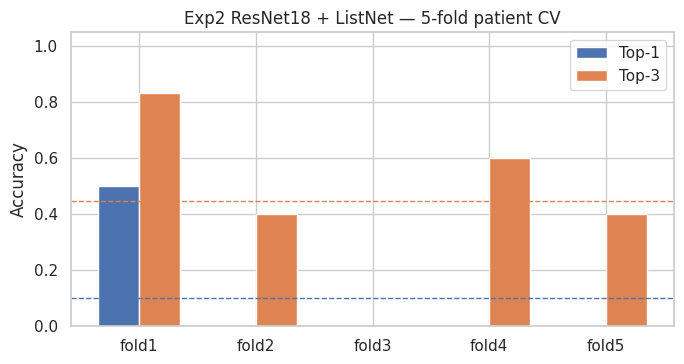

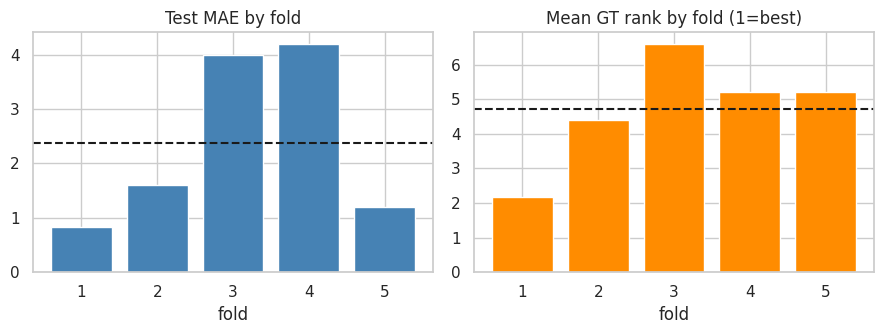

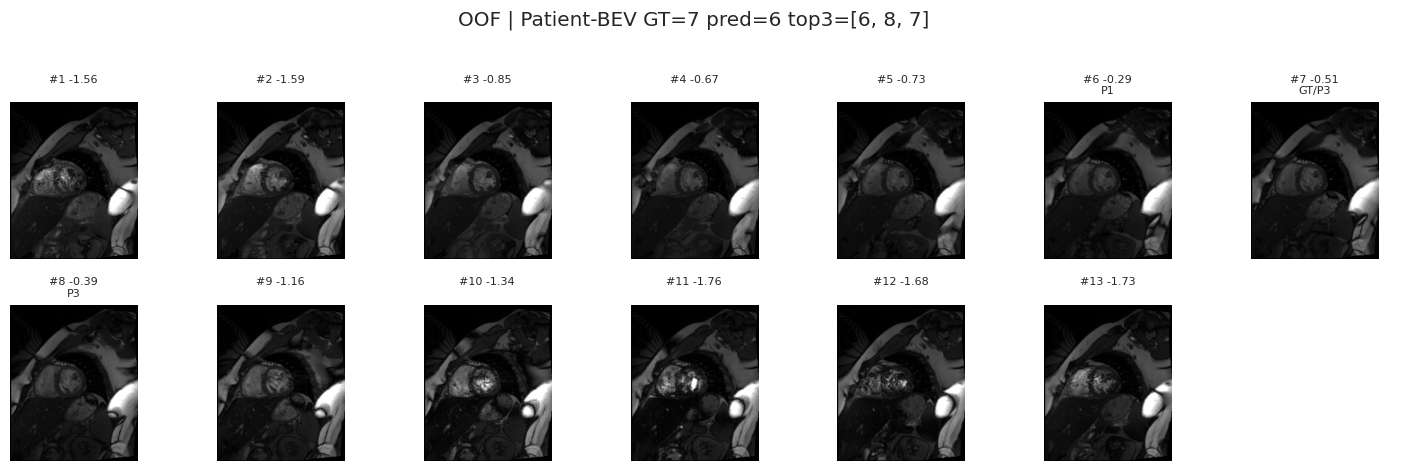

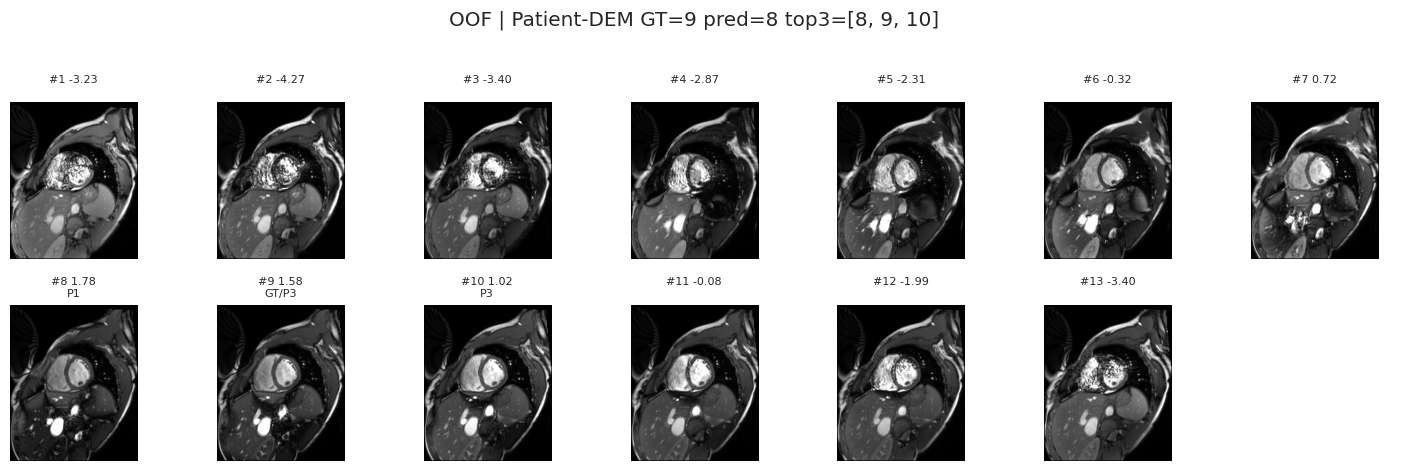

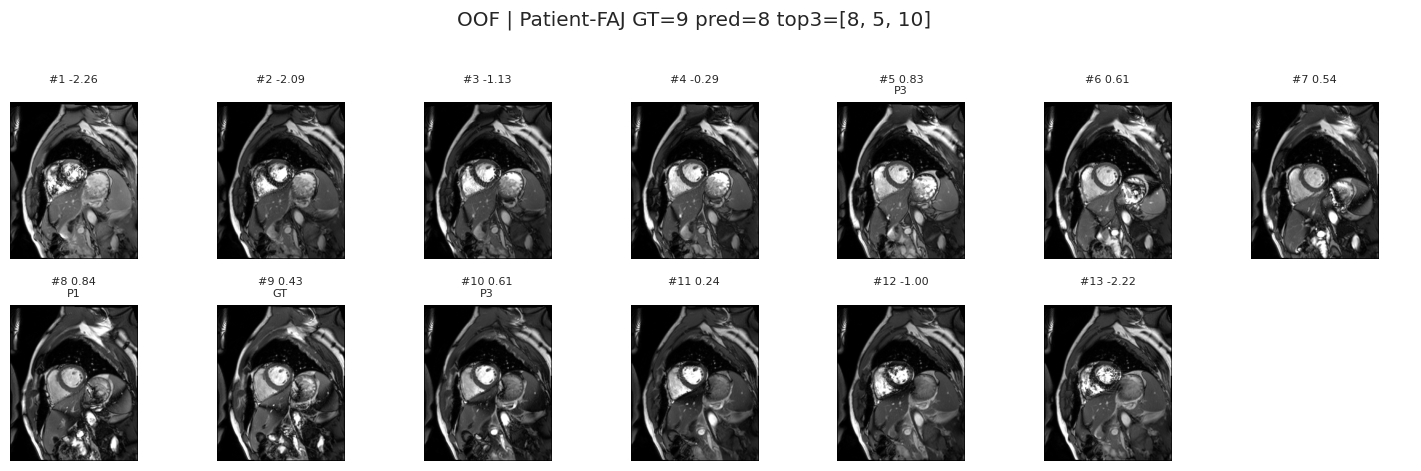

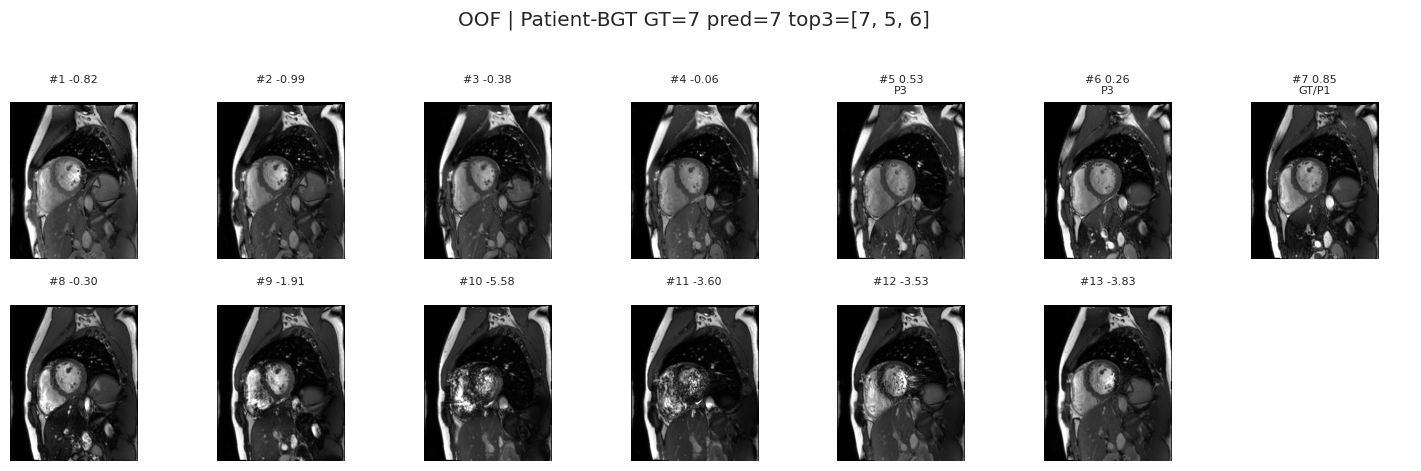

In [12]:
# Fold metric bars
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(fold_df))
w = 0.35
ax.bar(x - w/2, fold_df["top1_acc"], width=w, label="Top-1")
ax.bar(x + w/2, fold_df["top3_acc"], width=w, label="Top-3")
ax.axhline(fold_df["top1_acc"].mean(), color="C0", ls="--", lw=1)
ax.axhline(fold_df["top3_acc"].mean(), color="C1", ls="--", lw=1)
ax.set_xticks(x)
ax.set_xticklabels([f"fold{i}" for i in fold_df["fold"]])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accuracy")
ax.set_title("Exp2 ResNet18 + ListNet — 5-fold patient CV")
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "exp2_kfold_bars.png", dpi=140, bbox_inches="tight")
plt.show()

# MAE / rank
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].bar(fold_df["fold"], fold_df["mae"], color="steelblue")
axes[0].axhline(fold_df["mae"].mean(), color="k", ls="--")
axes[0].set_title("Test MAE by fold")
axes[0].set_xlabel("fold")
axes[1].bar(fold_df["fold"], fold_df["mean_rank_gt"], color="darkorange")
axes[1].axhline(fold_df["mean_rank_gt"].mean(), color="k", ls="--")
axes[1].set_title("Mean GT rank by fold (1=best)")
axes[1].set_xlabel("fold")
plt.tight_layout()
plt.savefig(OUT_DIR / "exp2_kfold_mae_rank.png", dpi=140, bbox_inches="tight")
plt.show()

# Visualize a few OOF mistakes / successes
show = ens_pp.sort_values(["top1_correct", "mae"]).head(3)["patient_id"].tolist()
show += ens_pp[ens_pp["top1_correct"] == 1]["patient_id"].head(2).tolist()
show = list(dict.fromkeys(show))[:4]

for pid in show:
    sub = oof_df[oof_df["patient_id"] == pid].sort_values("instance_no")
    gt = int(sub["gt_image_no"].iloc[0])
    ranked = sub.sort_values("score", ascending=False)["instance_no"].astype(int).tolist()
    paths = index_df[index_df["patient_id"] == pid].set_index("instance_no")["path"]
    n = len(sub)
    cols = min(7, n)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.1 * cols, 2.3 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, (_, r) in zip(axes, sub.iterrows()):
        ax.imshow(load_dicom_image(paths.loc[int(r["instance_no"])]), cmap="gray")
        inst = int(r["instance_no"])
        flags = []
        if inst == gt: flags.append("GT")
        if inst == ranked[0]: flags.append("P1")
        elif inst in ranked[:3]: flags.append("P3")
        ax.set_title(f"#{inst} {r['score']:.2f}\n{'/'.join(flags)}", fontsize=8)
        color = "lime" if inst == gt else ("dodgerblue" if inst == ranked[0] else ("orange" if inst in ranked[:3] else "0.3"))
        for spine in ax.spines.values():
            spine.set_color(color); spine.set_linewidth(2)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(f"OOF | {pid} GT={gt} pred={ranked[0]} top3={ranked[:3]}", y=1.02)
    plt.tight_layout()
    plt.show()


## 11. Optional LOOCV (gold standard for n=26)

Set `cfg.run_loocv = True` in the config cell and re-run from config, **or** flip the flag below. ~26 training runs — budget ~1–2h on T4 depending on early stop.


In [13]:
RUN_LOOCV = True  # or set True here

if RUN_LOOCV:
    loo = LeaveOneOut()
    loo_rows = []
    loo_preds = []
    pids_arr = np.array(labels_df["patient_id"].tolist())
    for fold, (tr_idx, te_idx) in enumerate(loo.split(pids_arr), 1):
        tr_p = pids_arr[tr_idx].tolist()
        te_p = pids_arr[te_idx].tolist()
        tr_fit, va_p = train_test_split(tr_p, test_size=0.15, random_state=cfg.seed + fold)
        # Shorter schedule for LOOCV runtime
        _ef, _eu = cfg.epochs_freeze, cfg.epochs_unfreeze
        cfg.epochs_freeze, cfg.epochs_unfreeze = 5, 15
        model, _ = train_fold(tr_fit, va_p, tag=f"loo{fold}_{te_p[0]}")
        cfg.epochs_freeze, cfg.epochs_unfreeze = _ef, _eu
        pred = predict_patients(model, index_df, te_p)
        m = patient_ranking_metrics(pred)
        loo_preds.append(pred)
        loo_rows.append({
            "fold": fold, "test_pid": te_p[0],
            "top1_acc": m["top1_acc"], "top3_acc": m["top3_acc"],
            "mae": m["mae"], "rank_gt": m["per_patient"]["rank_gt"].iloc[0],
        })
        print(f"LOO {fold:02d}/{len(pids_arr)} {te_p[0]}: "
              f"top1={m['top1_acc']} top3={m['top3_acc']} mae={m['mae']}")
        del model
        torch.cuda.empty_cache() if DEVICE.type == "cuda" else None

    loo_df = pd.DataFrame(loo_rows)
    loo_df.to_csv(OUT_DIR / "exp2_loocv_results.csv", index=False)
    loo_oof = pd.concat(loo_preds, ignore_index=True)
    loo_oof.to_csv(OUT_DIR / "exp2_loocv_oof_scores.csv", index=False)
    print("\n=== LOOCV summary ===")
    display(loo_df)
    print(loo_df[["top1_acc", "top3_acc", "mae", "rank_gt"]].agg(["mean", "std"]))
    display(patient_ranking_metrics(loo_oof)["per_patient"])
else:
    print("LOOCV skipped. Set RUN_LOOCV = True to enable.")



Train loo1_Patient-BEV  n_train=21 n_val=4
Ep 01 [freeze  ] tr=2.9526 va=2.8419 Top1=0.000 Top3=0.250 MAE=3.00 rank=5.00 *best*
Ep 02 [freeze  ] tr=2.7298 va=2.7326 Top1=0.000 Top3=0.250 MAE=2.75 rank=4.75 *best*
Ep 03 [freeze  ] tr=2.6627 va=2.6534 Top1=0.000 Top3=0.500 MAE=2.00 rank=4.00 *best*
Ep 04 [freeze  ] tr=2.5134 va=2.6023 Top1=0.000 Top3=0.500 MAE=2.00 rank=4.00
Ep 05 [freeze  ] tr=2.4865 va=2.5395 Top1=0.250 Top3=0.750 MAE=1.25 rank=3.25 *best*
-- unfreeze backbone @ epoch 6
Ep 08 [unfreeze] tr=2.3419 va=2.4199 Top1=0.250 Top3=0.750 MAE=1.25 rank=2.75
Ep 09 [unfreeze] tr=2.3525 va=2.4069 Top1=0.500 Top3=0.750 MAE=0.75 rank=2.50 *best*
Ep 10 [unfreeze] tr=2.3555 va=2.3870 Top1=0.750 Top3=0.750 MAE=0.25 rank=2.50 *best*
Ep 12 [unfreeze] tr=2.2614 va=2.3560 Top1=0.750 Top3=0.750 MAE=0.25 rank=2.50
Ep 16 [unfreeze] tr=2.1699 va=2.3301 Top1=0.750 Top3=0.750 MAE=0.25 rank=2.50
Early stop at epoch 18
Saved /kaggle/working/exp2_outputs/resnet18_loo1_Patient-BEV_best.pt
LOO 01/26 P

,fold,test_pid,top1_acc,top3_acc,mae,rank_gt
0,1,Patient-BEV,0.0,1.0,1.0,2
1,2,Patient-BGT,0.0,0.0,1.0,6
2,3,Patient-BVE,0.0,1.0,1.0,3
3,4,Patient-CEA,0.0,0.0,4.0,8
4,5,Patient-CEJP,0.0,1.0,2.0,3
5,6,Patient-DEM,0.0,1.0,1.0,2
6,7,Patient-FAJ,0.0,0.0,2.0,7
7,8,Patient-FEC,0.0,0.0,3.0,4
8,9,Patient-GJ,0.0,1.0,2.0,2
9,10,Patient-HMJ,0.0,0.0,1.0,4


      top1_acc  top3_acc       mae   rank_gt
mean  0.038462  0.461538  2.192308  4.076923
std   0.196116  0.508391  1.296741  2.331061


,patient_id,protocol,gt_image_no,pred_top1,pred_top3,top1_correct,top3_correct,mae,rank_gt
0,Patient-BEV,step25,7,6,"[6, 7, 5]",0,1,1,2
1,Patient-BGT,step25,7,8,"[8, 3, 5]",0,0,1,6
2,Patient-BVE,step25,6,7,"[7, 8, 6]",0,1,1,3
3,Patient-CEA,step25,7,11,"[11, 10, 5]",0,0,4,8
4,Patient-CEJP,step25,4,2,"[2, 13, 4]",0,1,2,3
5,Patient-DEM,step25,9,8,"[8, 9, 10]",0,1,1,2
6,Patient-FAJ,step25,9,7,"[7, 6, 10]",0,0,2,7
7,Patient-FEC,step25,8,5,"[5, 6, 7]",0,0,3,4
8,Patient-GJ,step25,9,11,"[11, 9, 13]",0,1,2,2
9,Patient-HMJ,step25,8,9,"[9, 6, 7]",0,0,1,4


---
### Outputs in `exp2_outputs/`
- `resnet18_fold*_best.pt` — fold checkpoints  
- `exp2_kfold_results.csv`, `exp2_oof_scores.csv`, `exp2_oof_per_patient.csv`  
- `exp2_vs_baselines.csv`, plots  
- optional `exp2_loocv_*.csv`

### How to read results vs Exp1
- Compare **OOF Top-1 / Top-3 / MAE** to Exp1’s single-split and 5-fold numbers.  
- Expect gains mainly from ListNet + freeze/unfreeze + MAE early-stop; Top-1 may still be hard with n=26.
